In [8]:
# Environment & Dataset
!pip install -q ultralytics
!unzip -o /content/dataset.zip -d /content/

Archive:  /content/dataset.zip
  inflating: /content/dataset/test/images/agri_0_1083.jpeg  
  inflating: /content/dataset/test/images/agri_0_114.jpeg  
  inflating: /content/dataset/test/images/agri_0_1334.jpeg  
  inflating: /content/dataset/test/images/agri_0_1351.jpeg  
  inflating: /content/dataset/test/images/agri_0_1420.jpeg  
  inflating: /content/dataset/test/images/agri_0_1499.jpeg  
  inflating: /content/dataset/test/images/agri_0_1693.jpeg  
  inflating: /content/dataset/test/images/agri_0_1731.jpeg  
  inflating: /content/dataset/test/images/agri_0_1771.jpeg  
  inflating: /content/dataset/test/images/agri_0_1868.jpeg  
  inflating: /content/dataset/test/images/agri_0_1960.jpeg  
  inflating: /content/dataset/test/images/agri_0_1990.jpeg  
  inflating: /content/dataset/test/images/agri_0_2077.jpeg  
  inflating: /content/dataset/test/images/agri_0_2121.jpeg  
  inflating: /content/dataset/test/images/agri_0_2256.jpeg  
  inflating: /content/dataset/test/images/agri_0_2271.j

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# Fine-Tuning YOLOv8n
from ultralytics import YOLO

# Load lightweight pretrained backbone
model = YOLO("yolov8n.pt")

# Train in Google Drive
results = model.train(
    data="/content/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    project="/content/drive/MyDrive/weed_detector_runs",
    name="yolov8n_capstone",
    seed=42,
    save=True
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_capstone-2, nbs=64, nms=None, opset=None, optimize=False, optim

--- Training Curves & Metrics ---


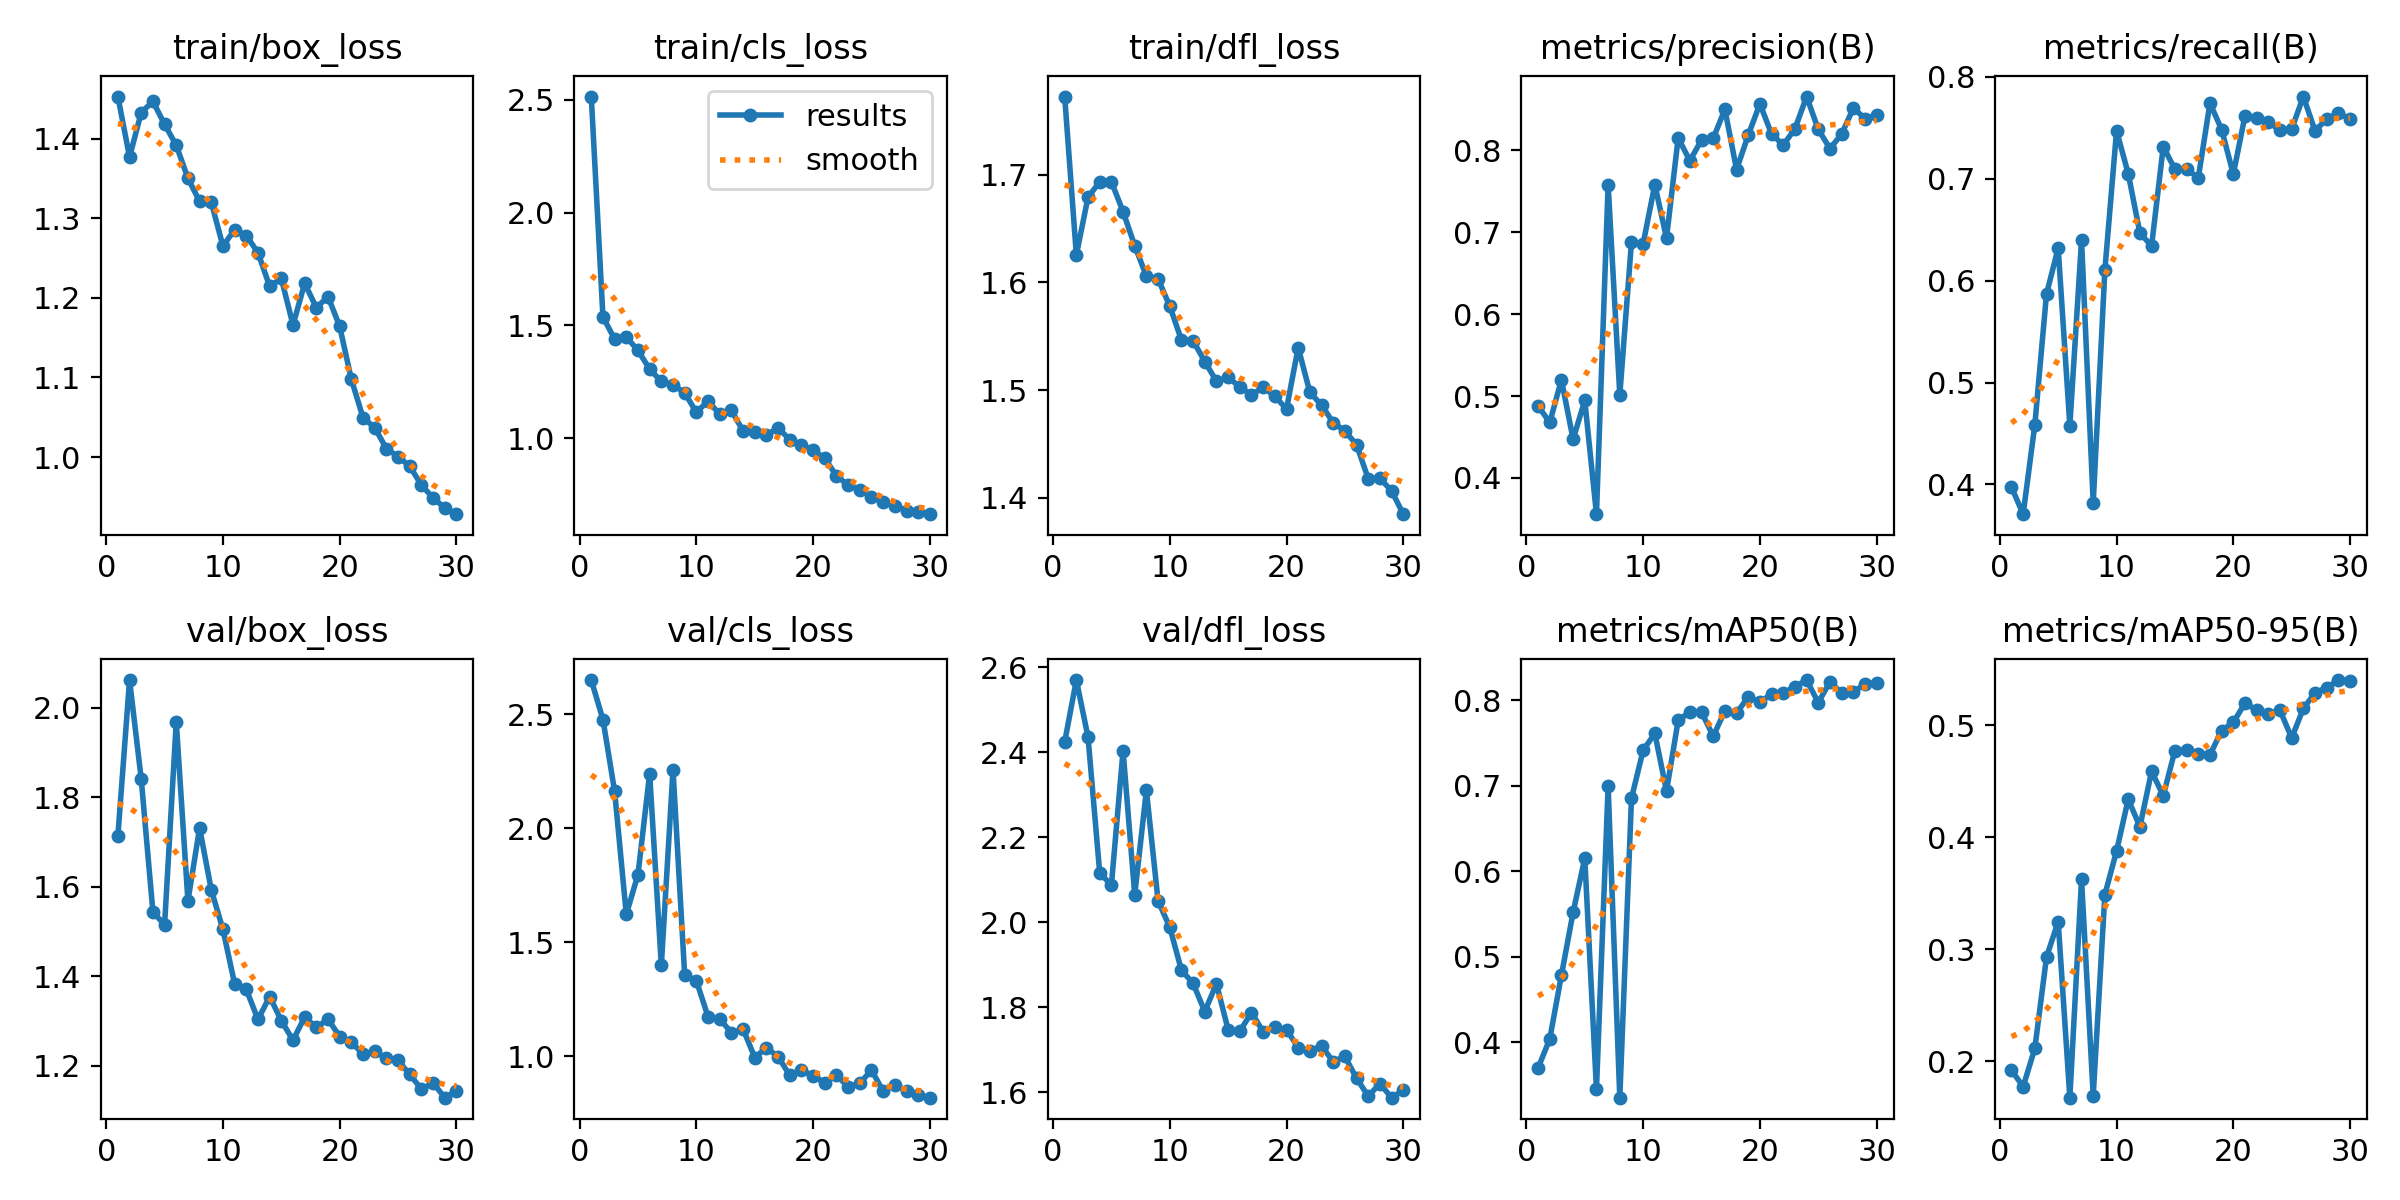


--- Confusion Matrix ---


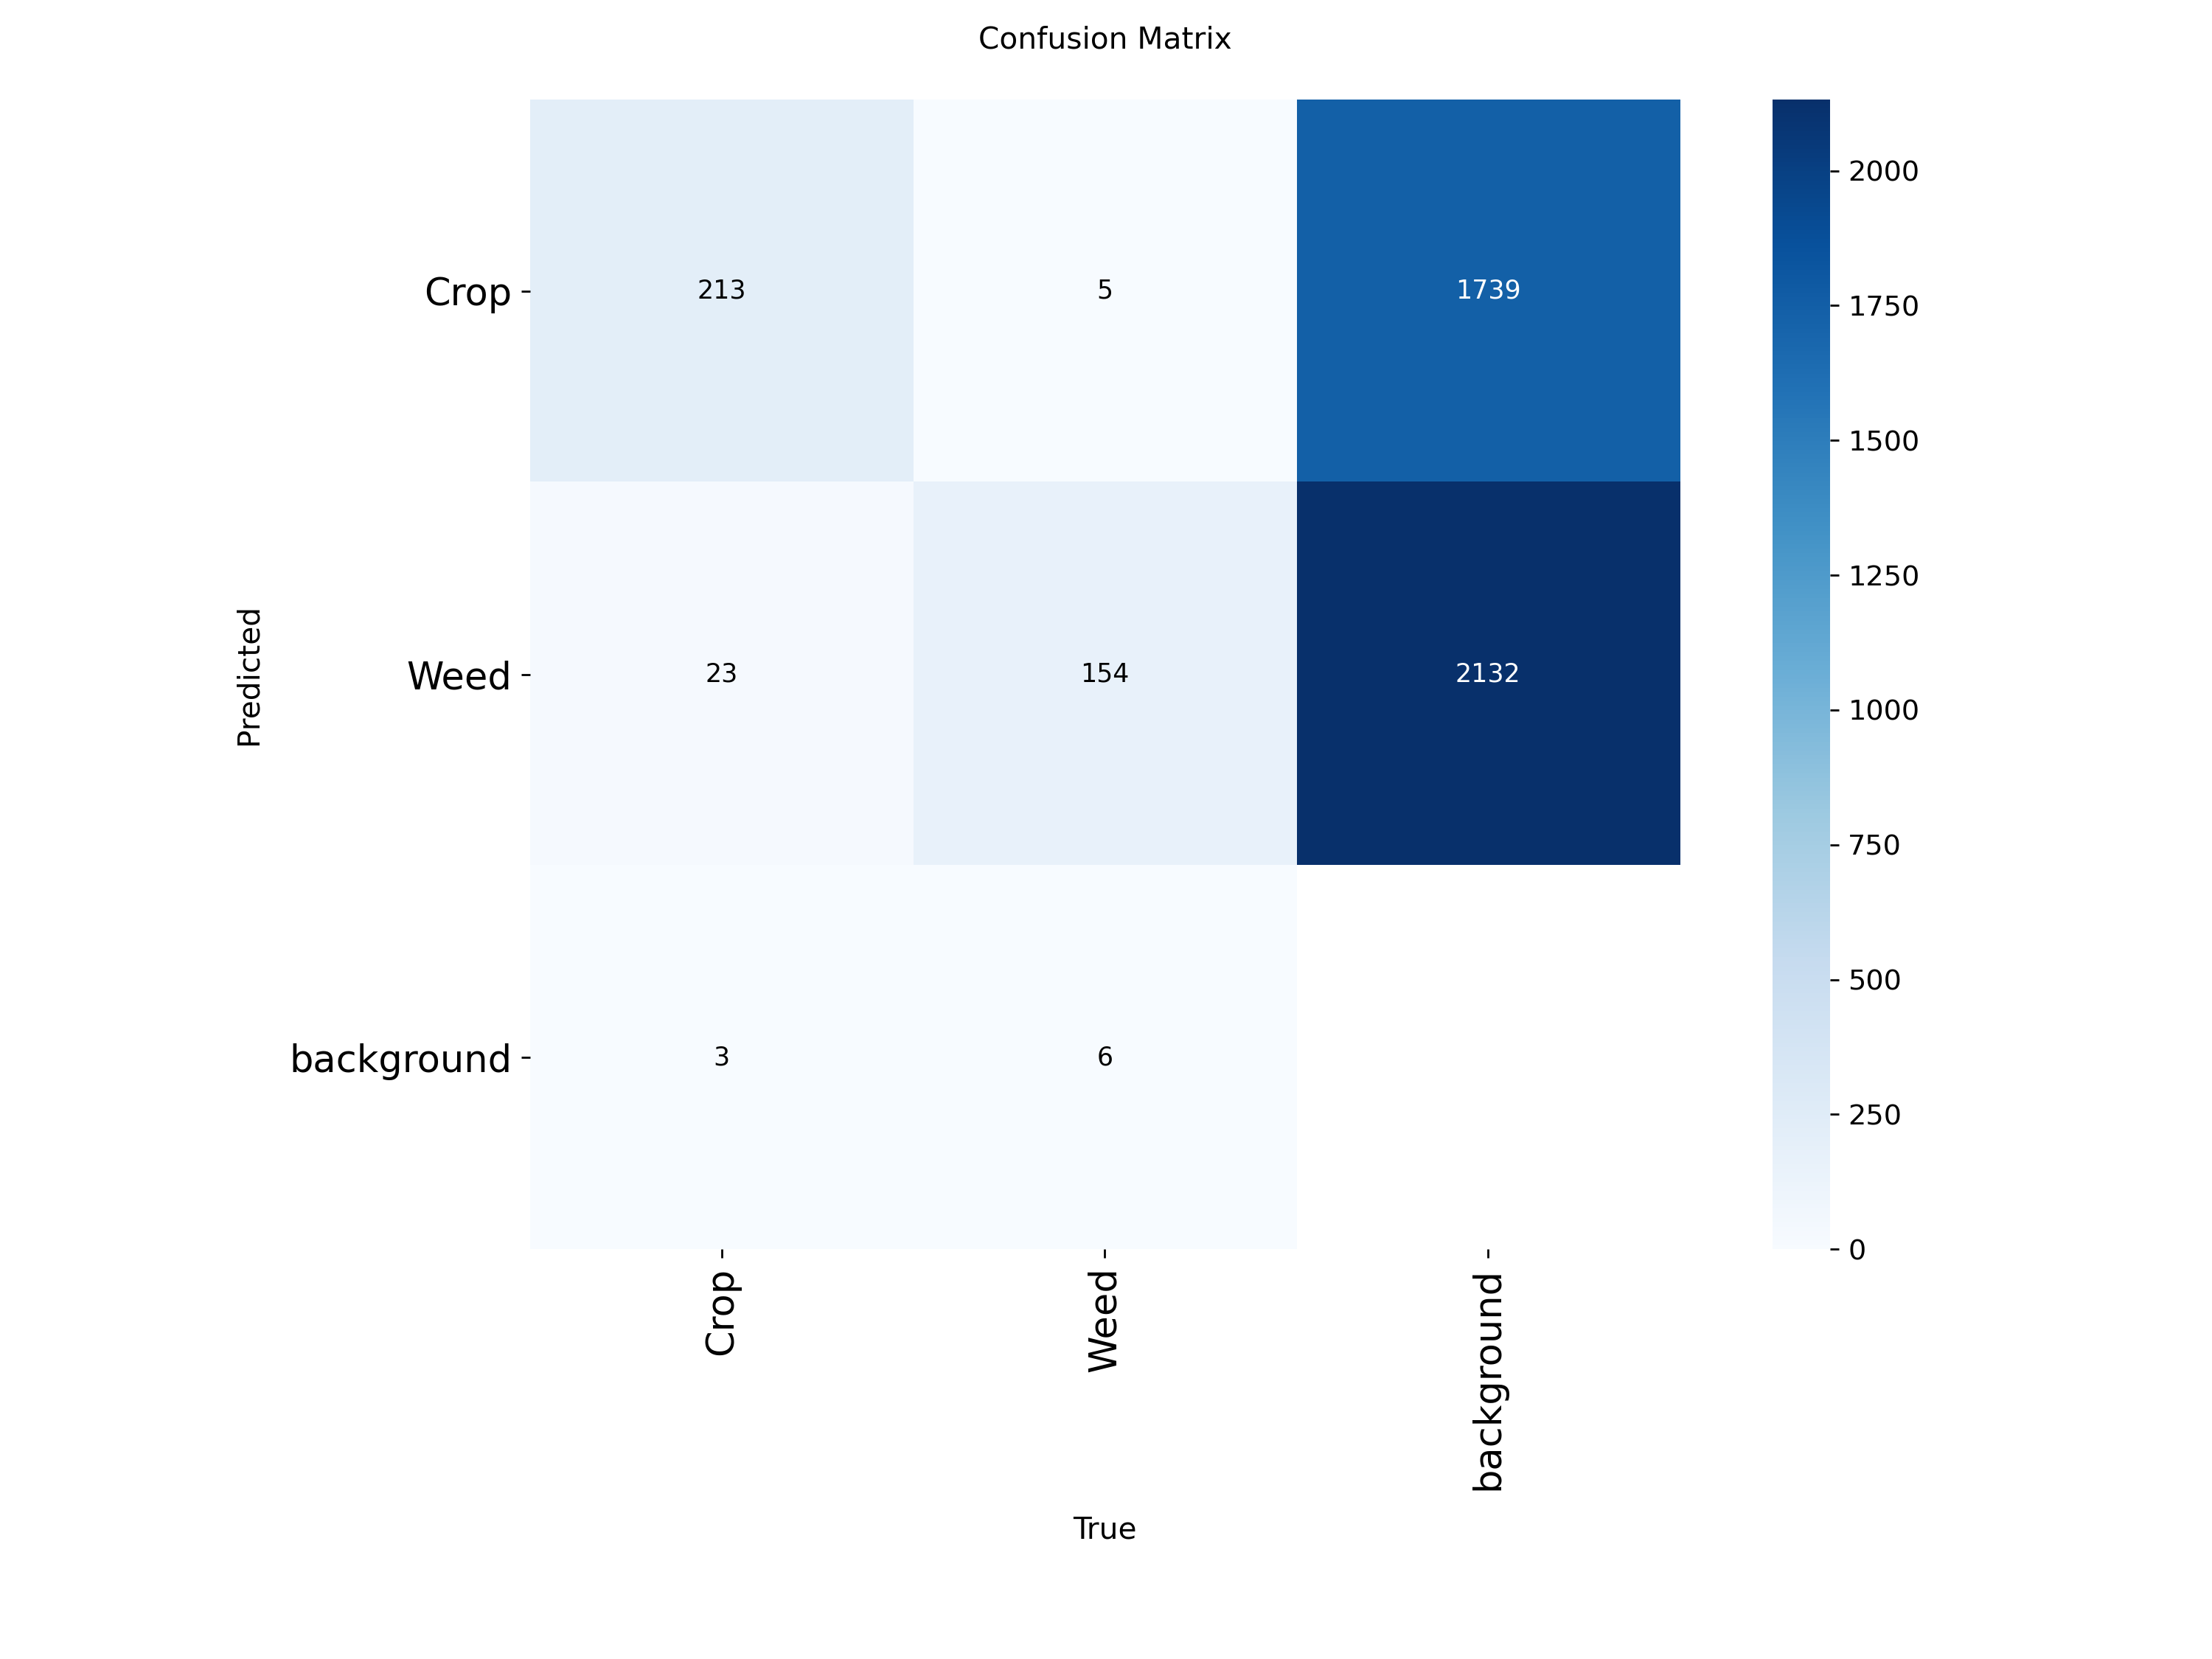

In [15]:
import os
from IPython.display import Image, display

# Direct path where YOLO saved the run
run_dir = "/content/drive/MyDrive/weed_detector_runs/yolov8n_capstone-2"

results_path = os.path.join(run_dir, "results.png")
cm_path = os.path.join(run_dir, "confusion_matrix.png")

if os.path.exists(results_path):
    print("--- Training Curves & Metrics ---")
    display(Image(filename=results_path))
else:
    print(f"Not found: {results_path}")

if os.path.exists(cm_path):
    print("\n--- Confusion Matrix ---")
    display(Image(filename=cm_path))
else:
    print(f"Not found: {cm_path}")

In [16]:
import glob
from ultralytics import YOLO

best_model = YOLO("/content/drive/MyDrive/weed_detector_runs/yolov8n_capstone-2/weights/best.pt")

# Run on 2 test images
test_imgs = glob.glob("/content/dataset/test/images/*.*")[:2]
results = best_model.predict(test_imgs, conf=0.35, save=True)

for i, r in enumerate(results):
    classes = r.boxes.cls.tolist()
    crops = classes.count(0)
    weeds = classes.count(1)
    total = len(classes)
    weed_ratio = (weeds / total * 100) if total > 0 else 0

    print(f"\n[Test Image {i+1}]")
    print(f"Total Detected: {total} | Crops: {crops} | Weeds: {weeds}")
    print(f"Weed Infestation Pressure: {weed_ratio:.1f}%")


0: 640x640 2 Weeds, 10.9ms
1: 640x640 1 Weed, 10.9ms
Speed: 2.4ms preprocess, 10.9ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict

[Test Image 1]
Total Detected: 2 | Crops: 0 | Weeds: 2
Weed Infestation Pressure: 100.0%

[Test Image 2]
Total Detected: 1 | Crops: 0 | Weeds: 1
Weed Infestation Pressure: 100.0%


In [17]:
best_model.export(format="onnx")
print("Model successfully converted to ONNX.")

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/weed_detector_runs/yolov8n_capstone-2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 351ms
Prepared 4 packages in 630ms
Installed 4 packages in 35ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2